# Семантические признаки музыкальных треков

В этой работе я взял по 50 позиций из двух заданных Spotify-плейлистов, извлёк признаки из 30-секундных preview и проверил два способа представления музыки: обычные аудио-признаки и эмбеддинги CLAP.

Главный вопрос: достаточно ли темпа, энергии и спектральных характеристик для поиска похожих треков, или предобученное аудио-представление работает лучше?

<a id="task-1"></a>
## Задание 1. Сбор датасета

Использованы только два плейлиста из условия:

1. [Daily Mix 6](https://open.spotify.com/playlist/37i9dQZF1E39FJtUzeh2UV?si=_zf3vFIMT5y3A2CdbfpPuA)
2. [VILLIAN Radio](https://open.spotify.com/playlist/37i9dQZF1E4wwkchMkSBWv?si=leedN1noRZGw2fTD14AyZQ)

Из каждого источника берутся первые 50 позиций в том порядке, который вернул Spotify. Ограничений по жанру или артисту нет: дополнительная фильтрация изменила бы заданную выборку. На момент сбора между плейлистами было три совпадающих трека. Поэтому исходная таблица содержит 100 позиций, а таблица уникальных треков — 97 строк.

Плейлисты алгоритмические и могут обновляться. В репозитории сохранён снимок с полем `collected_at_utc`, чтобы результаты ноутбука можно было воспроизвести на тех же данных.

In [1]:
!pip install pandas numpy requests librosa torch transformers scikit-learn matplotlib seaborn umap-learn tqdm -q

'pip' is not recognized as an internal or external command,
operable program or batch file.


In [2]:
import html
import json
import re
from datetime import datetime, timezone
from pathlib import Path

import librosa
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests
import seaborn as sns
import torch
import umap.umap_ as umap
from sklearn.manifold import TSNE
from sklearn.metrics import silhouette_score
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.preprocessing import StandardScaler
from tqdm.auto import tqdm
from transformers import ClapModel, ClapProcessor

RANDOM_STATE = 42
MODEL_NAME = 'laion/clap-htsat-unfused'
DATA_DIR = Path('data')
FIGURES_DIR = Path('results/figures')
DATA_DIR.mkdir(exist_ok=True)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

sns.set_theme(style='whitegrid', palette='colorblind')

In [3]:
PLAYLISTS = [
    {
        'playlist_id': '37i9dQZF1E39FJtUzeh2UV',
        'source_url': 'https://open.spotify.com/playlist/37i9dQZF1E39FJtUzeh2UV?si=_zf3vFIMT5y3A2CdbfpPuA'
    },
    {
        'playlist_id': '37i9dQZF1E4wwkchMkSBWv',
        'source_url': 'https://open.spotify.com/playlist/37i9dQZF1E4wwkchMkSBWv?si=leedN1noRZGw2fTD14AyZQ'
    }
]

def load_embed_data(playlist_id):
    url = f'https://open.spotify.com/embed/playlist/{playlist_id}'
    response = requests.get(url, timeout=30)
    response.raise_for_status()
    match = re.search(
        r'<script id="__NEXT_DATA__" type="application/json">(.*?)</script>',
        response.text
    )
    if not match:
        raise RuntimeError(f'playlist data not found: {playlist_id}')
    payload = json.loads(html.unescape(match.group(1)))
    return payload['props']['pageProps']['state']['data']['entity']

def collect_tracks(limit_per_playlist=50):
    rows = []
    collected_at = datetime.now(timezone.utc).isoformat(timespec='seconds')

    for playlist in PLAYLISTS:
        entity = load_embed_data(playlist['playlist_id'])
        tracks = entity['trackList'][:limit_per_playlist]
        if len(tracks) != limit_per_playlist:
            raise RuntimeError(f"expected {limit_per_playlist} tracks, got {len(tracks)}")

        for position, track in enumerate(tracks, start=1):
            preview = track.get('audioPreview') or {}
            track_id = track['uri'].split(':')[-1]
            rows.append({
                'playlist_id': playlist['playlist_id'],
                'playlist_name': entity['name'],
                'playlist_position': position,
                'track_id': track_id,
                'track_name': track['title'],
                'artist_name': track['subtitle'],
                'duration_ms': track['duration'],
                'explicit': track['isExplicit'],
                'spotify_url': f'https://open.spotify.com/track/{track_id}',
                'preview_url': preview.get('url'),
                'source_url': playlist['source_url'],
                'collected_at_utc': collected_at
            })

    raw = pd.DataFrame(rows)
    if raw['preview_url'].isna().any():
        raise RuntimeError('some tracks have no preview')
    return raw

def make_unique_dataset(raw):
    rows = []
    for _, group in raw.groupby('track_id', sort=False):
        row = group.iloc[0].to_dict()
        row['playlist_id'] = ' | '.join(group['playlist_id'].unique())
        row['playlist_name'] = ' | '.join(group['playlist_name'].unique())
        row['playlist_position'] = ' | '.join(
            f"{item.playlist_name}: {item.playlist_position}"
            for item in group.itertuples()
        )
        row['source_url'] = ' | '.join(group['source_url'].unique())
        row['playlist_count'] = int(group['playlist_id'].nunique())
        rows.append(row)
    return pd.DataFrame(rows)

In [4]:
raw_path = DATA_DIR / 'spotify_playlist_tracks_raw.csv'
unique_path = DATA_DIR / 'music_dataset.csv'

if raw_path.exists() and unique_path.exists():
    raw_df = pd.read_csv(raw_path)
    tracks_df = pd.read_csv(unique_path)
else:
    raw_df = collect_tracks(50)
    tracks_df = make_unique_dataset(raw_df)
    raw_df.to_csv(raw_path, index=False, encoding='utf-8-sig')
    tracks_df.to_csv(unique_path, index=False, encoding='utf-8-sig')

collection_check = pd.DataFrame({
    'value': [
        len(raw_df),
        raw_df['track_id'].nunique(),
        len(raw_df) - raw_df['track_id'].nunique(),
        raw_df['preview_url'].notna().sum(),
        raw_df['artist_name'].nunique(),
        raw_df['artist_name'].value_counts().max()
    ]
}, index=[
    'playlist positions',
    'unique tracks',
    'duplicate positions',
    'positions with preview',
    'unique artist strings',
    'maximum positions for one artist string'
])

display(raw_df.groupby(['playlist_id', 'playlist_name']).size().rename('tracks').to_frame())
display(collection_check)
display(raw_df.head())

,,tracks
playlist_id,playlist_name,
37i9dQZF1E39FJtUzeh2UV,Daily Mix 6,50
37i9dQZF1E4wwkchMkSBWv,VILLIAN Radio,50


,value
playlist positions,100
unique tracks,97
duplicate positions,3
positions with preview,100
unique artist strings,59
maximum positions for one artist string,8


,playlist_id,playlist_name,playlist_position,track_id,track_name,artist_name,duration_ms,explicit,spotify_url,preview_url,source_url,collected_at_utc
0,37i9dQZF1E39FJtUzeh2UV,Daily Mix 6,1,42nRlLStzW9x6vXUzQ16W5,супермаркет,madk1d,119172,True,https://open.spotify.com/track/42nRlLStzW9x6vX...,https://p.scdn.co/mp3-preview/4f643d86a287ea79...,https://open.spotify.com/playlist/37i9dQZF1E39...,2026-10-25T18:06:47+00:00
1,37i9dQZF1E39FJtUzeh2UV,Daily Mix 6,2,51NBhyVwxeUloodHDy9JgL,проклятье,greyrock,124983,True,https://open.spotify.com/track/51NBhyVwxeUlood...,https://p.scdn.co/mp3-preview/79d2bf9dfda32b2d...,https://open.spotify.com/playlist/37i9dQZF1E39...,2026-10-25T18:06:47+00:00
2,37i9dQZF1E39FJtUzeh2UV,Daily Mix 6,3,3weS9263Cl4teij5OiPVpo,лошков,Поларойд,89043,True,https://open.spotify.com/track/3weS9263Cl4teij...,https://p.scdn.co/mp3-preview/80e15bdf8554870f...,https://open.spotify.com/playlist/37i9dQZF1E39...,2026-10-25T18:06:47+00:00
3,37i9dQZF1E39FJtUzeh2UV,Daily Mix 6,4,3wOM6MY3KmA5470mfYbH6K,ты в моих мыслях навсегда,"урал гайсин, снялцепи",117708,False,https://open.spotify.com/track/3wOM6MY3KmA5470...,https://p.scdn.co/mp3-preview/15c54c52c3117dd0...,https://open.spotify.com/playlist/37i9dQZF1E39...,2026-10-25T18:06:47+00:00
4,37i9dQZF1E39FJtUzeh2UV,Daily Mix 6,5,5JxsjEarrb9v3KFCWfGPcS,SUBSTANCE,"luvdakash, unki",140793,True,https://open.spotify.com/track/5JxsjEarrb9v3KF...,https://p.scdn.co/mp3-preview/510b22102381353d...,https://open.spotify.com/playlist/37i9dQZF1E39...,2026-10-25T18:06:47+00:00


### Что именно попало в датасет

Для каждой позиции сохранены название, исполнитель, длительность, explicit-флаг, номер в плейлисте, ссылка на Spotify и ссылка на preview. `artist_name` хранится так, как его показал Spotify: если исполнителей несколько, они остаются одной строкой.

Отдельный лимит на одного артиста не вводился. В этой фиксированной выборке максимум равен восьми позициям одного artist string. Это создаёт смещение, но честно отражает содержимое заданных плейлистов.

<a id="task-2"></a>
## Задание 2. Формирование набора признаков

Я использую четыре группы признаков:

| Группа | Признаки | Зачем в рекомендациях |
|---|---|---|
| Метаданные | плейлист, позиция, исполнитель, длительность, explicit | фильтры и анализ источника |
| Ритм и энергия | tempo, RMS, onset rate | различают спокойные и активные треки |
| Тембр | spectral centroid, bandwidth, rolloff, ZCR, chroma, 13 MFCC | помогают находить похожее звучание даже у разных артистов |
| Семантика | genre, mood, context, atmosphere | позволяют объяснять рекомендации понятными словами |
| CLAP embedding | вектор из 512 чисел | более полное аудио-представление для поиска соседей |

Жанр, настроение, контекст и атмосфера предсказываются zero-shot: CLAP сравнивает аудиофрагмент с набором текстовых описаний. Это не ручная разметка и не ground truth, поэтому рядом сохраняется score выбранной метки.

<a id="task-3"></a>
## Задание 3. Извлечение признаков

Для обычных аудио-признаков используется `librosa`. Она быстро считает темп, энергию, атаки, спектр и MFCC, а результаты легко интерпретировать.

Для более содержательного представления используется предобученная модель `laion/clap-htsat-unfused`. CLAP обучена сближать аудио и текст, поэтому один и тот же embedding можно применять для похожести и zero-shot классификации.

Альтернативы, которые я рассматривал:

- Spotify Audio Features: удобны, но доступ к endpoint ограничен для новых приложений
- LLM по названию и артисту: дешёвая разметка, но модель не слышит аудио
- OpenL3 или VGGish: подходят для эмбеддингов, но хуже работают с текстовыми классами
- ручная разметка: лучше для проверки качества, но требует нескольких независимых оценщиков

Ниже находится полный код извлечения. Если готовые CSV и NPY уже лежат рядом с ноутбуком, они загружаются; при запуске в чистом Colab признаки считаются заново.

In [5]:
LABELS = {
    'genre': [
        'hip hop', 'trap', 'pop', 'electronic', 'rock', 'indie',
        'r&b', 'jazz', 'classical', 'ambient'
    ],
    'mood': [
        'energetic', 'calm', 'dark', 'melancholic',
        'happy', 'aggressive', 'dreamy', 'romantic'
    ],
    'context': [
        'workout', 'party', 'study', 'work',
        'sleep', 'chill', 'driving', 'gaming'
    ],
    'atmosphere': [
        'intimate', 'epic', 'minimal', 'atmospheric',
        'tense', 'warm', 'cold', 'cinematic'
    ]
}

def extract_librosa_features(audio, sample_rate):
    tempo, _ = librosa.beat.beat_track(y=audio, sr=sample_rate)
    rms = librosa.feature.rms(y=audio)
    centroid = librosa.feature.spectral_centroid(y=audio, sr=sample_rate)
    bandwidth = librosa.feature.spectral_bandwidth(y=audio, sr=sample_rate)
    rolloff = librosa.feature.spectral_rolloff(y=audio, sr=sample_rate)
    zcr = librosa.feature.zero_crossing_rate(audio)
    chroma = librosa.feature.chroma_stft(y=audio, sr=sample_rate)
    mfcc = librosa.feature.mfcc(y=audio, sr=sample_rate, n_mfcc=13)
    onsets = librosa.onset.onset_detect(y=audio, sr=sample_rate, units='time')

    features = {
        'tempo': float(np.asarray(tempo).reshape(-1)[0]),
        'rms': float(rms.mean()),
        'onset_rate': float(len(onsets) / (len(audio) / sample_rate)),
        'spectral_centroid': float(centroid.mean()),
        'spectral_bandwidth': float(bandwidth.mean()),
        'spectral_rolloff': float(rolloff.mean()),
        'zero_crossing_rate': float(zcr.mean()),
        'chroma_std': float(chroma.mean(axis=1).std())
    }
    features.update({
        f'mfcc_{index + 1}': float(value)
        for index, value in enumerate(mfcc.mean(axis=1))
    })
    return features

def unwrap_embedding(output):
    if hasattr(output, 'pooler_output'):
        return output.pooler_output
    return output

def process_audio(processor, audio):
    try:
        return processor(audio=audio, sampling_rate=48000, return_tensors='pt')
    except (TypeError, ValueError):
        return processor(audios=audio, sampling_rate=48000, return_tensors='pt')

def get_audio_embedding(model, processor, audio):
    inputs = process_audio(processor, audio)
    with torch.inference_mode():
        output = model.get_audio_features(**inputs)
    return unwrap_embedding(output)[0].cpu().numpy().astype('float32')

def get_text_embeddings(model, processor, labels):
    prompts = [f'a music track that sounds {label}' for label in labels]
    inputs = processor(text=prompts, padding=True, return_tensors='pt')
    with torch.inference_mode():
        output = model.get_text_features(**inputs)
    return unwrap_embedding(output).cpu().numpy().astype('float32')

def choose_label(audio_embeddings, text_embeddings, labels):
    scores = cosine_similarity(audio_embeddings, text_embeddings)
    best_indices = scores.argmax(axis=1)
    predicted = [labels[index] for index in best_indices]
    confidence = scores[np.arange(len(scores)), best_indices]
    return predicted, confidence

In [6]:
enriched_path = DATA_DIR / 'music_dataset_enriched.csv'
features_path = DATA_DIR / 'audio_features.csv'
clap_path = DATA_DIR / 'clap_embeddings.npy'
low_level_path = DATA_DIR / 'low_level_embeddings.npy'

if all(path.exists() for path in [enriched_path, features_path, clap_path, low_level_path]):
    df = pd.read_csv(enriched_path)
    audio_features = pd.read_csv(features_path)
    clap_embeddings = np.load(clap_path)
    low_level_embeddings = np.load(low_level_path)
else:
    processor = ClapProcessor.from_pretrained(MODEL_NAME)
    model = ClapModel.from_pretrained(MODEL_NAME).eval()
    preview_path = DATA_DIR / '_preview.mp3'
    feature_rows = []
    embedding_rows = []

    for track in tqdm(tracks_df.itertuples(), total=len(tracks_df), desc='audio features'):
        response = requests.get(track.preview_url, timeout=60)
        response.raise_for_status()
        preview_path.write_bytes(response.content)
        audio_48k, _ = librosa.load(str(preview_path), sr=48000, mono=True)
        audio_22k = librosa.resample(audio_48k, orig_sr=48000, target_sr=22050)

        feature_row = {'track_id': track.track_id}
        feature_row.update(extract_librosa_features(audio_22k, 22050))
        feature_rows.append(feature_row)
        embedding_rows.append(get_audio_embedding(model, processor, audio_48k))

    preview_path.unlink(missing_ok=True)
    audio_features = pd.DataFrame(feature_rows)
    clap_embeddings = np.vstack(embedding_rows)
    df = tracks_df.merge(audio_features, on='track_id', validate='one_to_one')

    for label_type, labels in LABELS.items():
        text_embeddings = get_text_embeddings(model, processor, labels)
        predicted, confidence = choose_label(clap_embeddings, text_embeddings, labels)
        df[label_type] = predicted
        df[f'{label_type}_score'] = confidence

    low_level_columns = [
        'tempo', 'rms', 'onset_rate', 'spectral_centroid',
        'spectral_bandwidth', 'spectral_rolloff',
        'zero_crossing_rate', 'chroma_std'
    ] + [f'mfcc_{index}' for index in range(1, 14)]
    low_level_embeddings = StandardScaler().fit_transform(df[low_level_columns])

    df.to_csv(enriched_path, index=False, encoding='utf-8-sig')
    audio_features.to_csv(features_path, index=False)
    np.save(clap_path, clap_embeddings)
    np.save(low_level_path, low_level_embeddings)

print(f'dataset shape: {df.shape}')
print(f'CLAP shape: {clap_embeddings.shape}')
display(df[['track_name', 'artist_name', 'genre', 'mood', 'context', 'atmosphere']].head(10))

dataset shape: (97, 42)
CLAP shape: (97, 512)


,track_name,artist_name,genre,mood,context,atmosphere
0,супермаркет,madk1d,electronic,energetic,party,epic
1,проклятье,greyrock,hip hop,energetic,work,epic
2,лошков,Поларойд,hip hop,energetic,work,epic
3,ты в моих мыслях навсегда,"урал гайсин, снялцепи",rock,energetic,party,epic
4,SUBSTANCE,"luvdakash, unki",hip hop,happy,study,warm
5,кровь на рубашке,"#вечныйкод, virginiawontcry",rock,energetic,party,warm
6,подделка,паранойя,hip hop,energetic,work,epic
7,самый лучший трудовик,madk1d,rock,energetic,party,epic
8,Judge,"silver gloria, @suffocated",hip hop,energetic,study,epic
9,infinity mirror,elox1m,hip hop,aggressive,party,epic


<a id="task-4"></a>
## Задание 4. Анализ данных

EDA проводится на двух уровнях. Для состава источников используется исходная таблица из 100 позиций. Для аудио-признаков и семантики используются 97 уникальных треков, чтобы три пересечения не получили двойной вес.

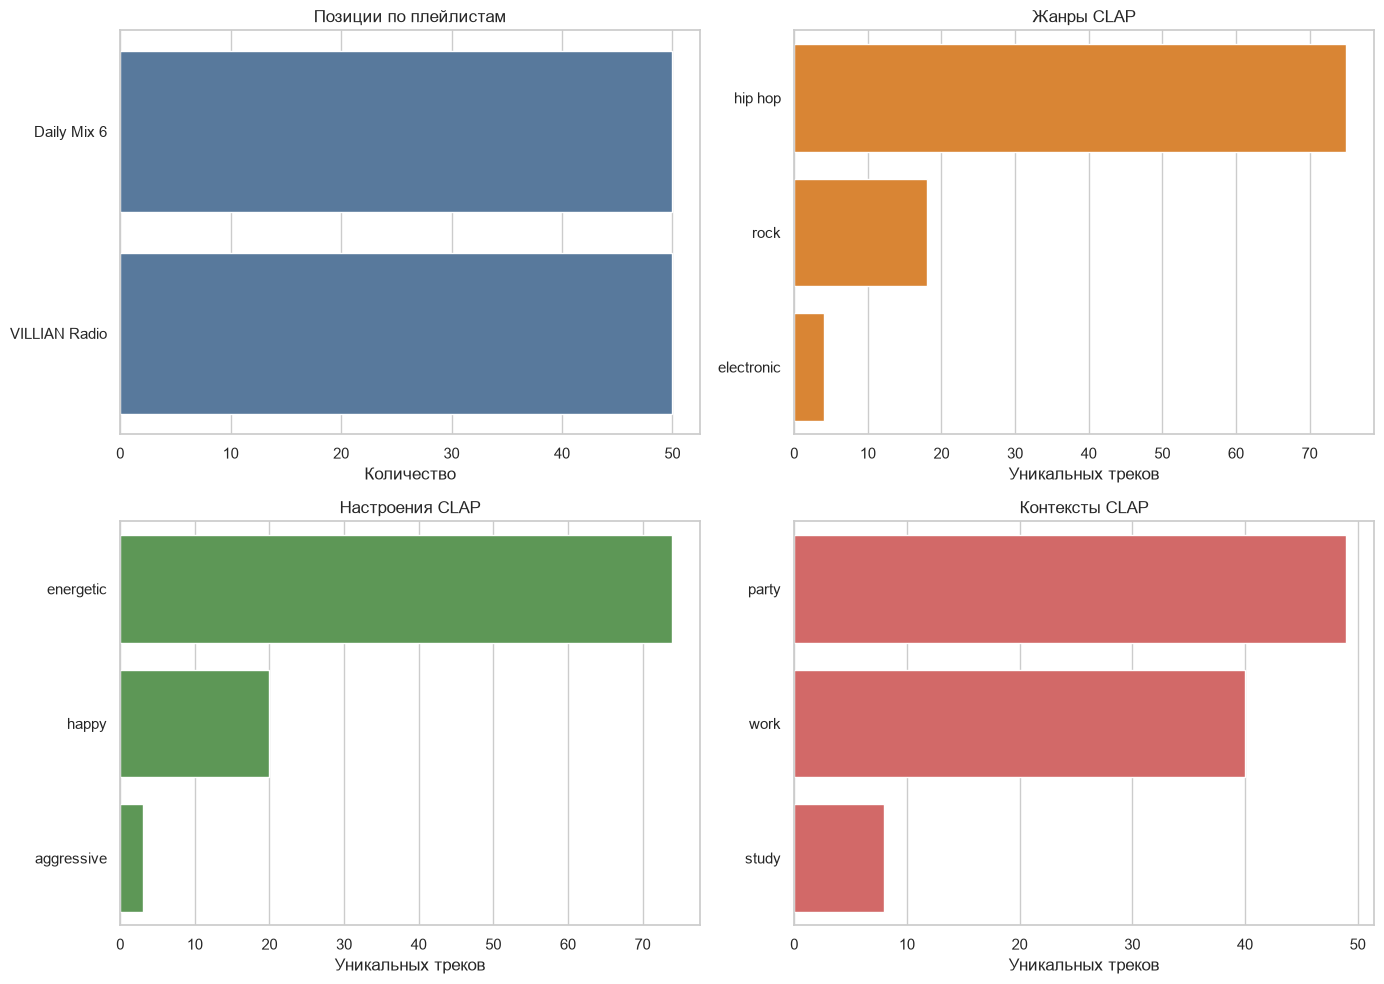

In [7]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

sns.countplot(
    data=raw_df,
    y='playlist_name',
    order=raw_df['playlist_name'].value_counts().index,
    ax=axes[0, 0],
    color='#4c78a8'
)
axes[0, 0].set_title('Позиции по плейлистам')
axes[0, 0].set_xlabel('Количество')
axes[0, 0].set_ylabel('')

for column, axis, color, title in [
    ('genre', axes[0, 1], '#f58518', 'Жанры CLAP'),
    ('mood', axes[1, 0], '#54a24b', 'Настроения CLAP'),
    ('context', axes[1, 1], '#e45756', 'Контексты CLAP')
]:
    sns.countplot(data=df, y=column, order=df[column].value_counts().index, ax=axis, color=color)
    axis.set_title(title)
    axis.set_xlabel('Уникальных треков')
    axis.set_ylabel('')

plt.tight_layout()
plt.savefig(FIGURES_DIR / 'distributions.png', dpi=160, bbox_inches='tight')
plt.show()

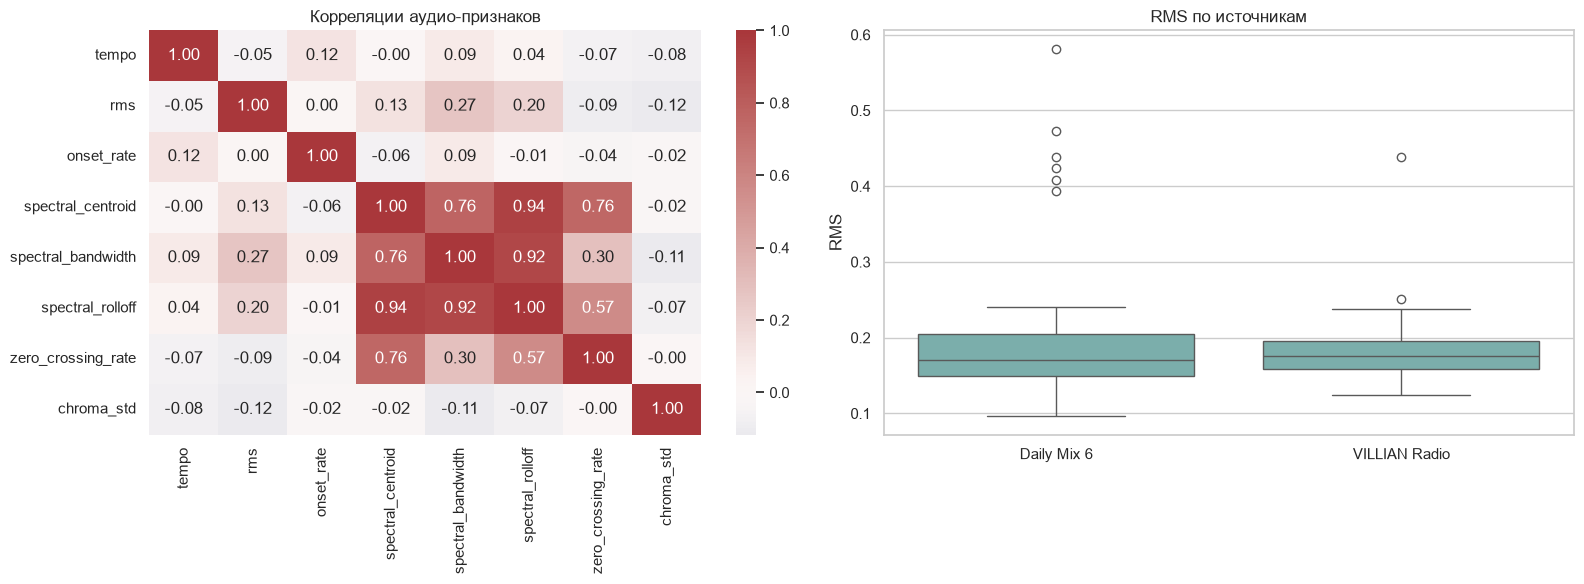

playlist_name,Daily Mix 6,VILLIAN Radio
genre,,
electronic,2,2
hip hop,34,38
rock,11,7


In [8]:
base_features = [
    'tempo', 'rms', 'onset_rate', 'spectral_centroid',
    'spectral_bandwidth', 'spectral_rolloff',
    'zero_crossing_rate', 'chroma_std'
]

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

correlations = df[base_features].corr()
sns.heatmap(correlations, cmap='vlag', center=0, annot=True, fmt='.2f', ax=axes[0])
axes[0].set_title('Корреляции аудио-признаков')

single_playlist = df[df['playlist_count'] == 1]
sns.boxplot(data=single_playlist, x='playlist_name', y='rms', ax=axes[1], color='#72b7b2')
axes[1].set_title('RMS по источникам')
axes[1].set_xlabel('')
axes[1].set_ylabel('RMS')

plt.tight_layout()
plt.savefig(FIGURES_DIR / 'audio_eda.png', dpi=160, bbox_inches='tight')
plt.show()

display(pd.crosstab(single_playlist['genre'], single_playlist['playlist_name']))

In [9]:
summary = pd.DataFrame({
    'count': [
        len(raw_df),
        len(df),
        df['artist_name'].nunique(),
        df['genre'].nunique(),
        df['mood'].nunique(),
        df['context'].nunique()
    ]
}, index=[
    'playlist positions',
    'unique tracks',
    'unique artist strings',
    'predicted genres',
    'predicted moods',
    'predicted contexts'
])

display(summary)
display(df[['genre_score', 'mood_score', 'context_score', 'atmosphere_score']].describe().round(3))

,count
playlist positions,100
unique tracks,97
unique artist strings,59
predicted genres,3
predicted moods,3
predicted contexts,3


,genre_score,mood_score,context_score,atmosphere_score
count,97.000,97.000,97.000,97.000
mean,0.423,0.366,0.404,0.334
std,0.056,0.049,0.049,0.054
min,0.289,0.241,0.280,0.216
25%,0.391,0.330,0.376,0.296
50%,0.415,0.364,0.402,0.334
75%,0.464,0.400,0.437,0.374
max,0.549,0.461,0.515,0.462


### Выводы из EDA

- Источники формально равны по размеру: по 50 позиций.
- После удаления трёх пересечений остаётся 97 уникальных треков.
- Выборка жанрово смещена в hip-hop. Это ожидаемо для данных плейлистов и не исправлялось искусственной балансировкой.
- Большая часть zero-shot меток относится к energetic, party и epic. Значит, по контексту датасет тоже узкий.
- Спектральный центроид, bandwidth и rolloff заметно коррелируют. Если использовать их одновременно без стандартизации, высокочастотная составляющая получит слишком большой вес.
- CLAP score не является вероятностью. Он нужен для сравнения вариантов внутри фиксированного словаря меток.

<a id="task-5"></a>
## Задание 5. Эксперименты с представлением треков

Сравниваются два пространства:

1. 21 стандартизованный признак: восемь базовых характеристик и 13 MFCC
2. 512-мерный CLAP embedding

В обоих случаях используется cosine similarity. UMAP и t-SNE строятся по CLAP-векторам, а ближайшие треки выводятся для обоих подходов.

In [10]:
low_similarity = cosine_similarity(low_level_embeddings)
clap_similarity = cosine_similarity(clap_embeddings)

def get_neighbors(track_index, similarity_matrix, count=5):
    neighbor_indices = np.argsort(similarity_matrix[track_index])[::-1][1:count + 1]
    columns = ['track_name', 'artist_name', 'playlist_name', 'genre', 'mood', 'context']
    result = df.iloc[neighbor_indices][columns].copy()
    result['similarity'] = similarity_matrix[track_index, neighbor_indices]
    return result

for track_index in [0, 48, 80]:
    track = df.iloc[track_index]
    print(f"{track['track_name']} / {track['artist_name']}")
    print('low-level features')
    display(get_neighbors(track_index, low_similarity))
    print('CLAP')
    display(get_neighbors(track_index, clap_similarity))

супермаркет / madk1d
low-level features


,track_name,artist_name,playlist_name,genre,mood,context,similarity
71,sexyswag2010,madk1d,VILLIAN Radio,hip hop,energetic,party,0.697454
61,дырки в штанах,madk1d,VILLIAN Radio,hip hop,energetic,party,0.685608
44,тварь,диссоциативное расстройство,Daily Mix 6,rock,energetic,party,0.630827
5,кровь на рубашке,"#вечныйкод, virginiawontcry",Daily Mix 6,rock,energetic,party,0.569859
14,грустная история,madk1d,Daily Mix 6,hip hop,energetic,work,0.448509


CLAP


,track_name,artist_name,playlist_name,genre,mood,context,similarity
56,Простужен,"FORTUNA 812, madk1d",VILLIAN Radio,hip hop,energetic,party,0.857294
48,планы,7nX,Daily Mix 6,hip hop,energetic,work,0.849791
38,временные петли,lafkrat,Daily Mix 6,hip hop,energetic,work,0.823798
14,грустная история,madk1d,Daily Mix 6,hip hop,energetic,work,0.823268
2,лошков,Поларойд,Daily Mix 6,hip hop,energetic,work,0.821448


планы / 7nX
low-level features


...

,track_name,artist_name,playlist_name,genre,mood,context,similarity
1,проклятье,greyrock,Daily Mix 6,hip hop,energetic,work,0.946115
71,sexyswag2010,madk1d,VILLIAN Radio,hip hop,energetic,party,0.942984
92,ты че обиделась,"madk1d, тёмный принц",VILLIAN Radio,hip hop,energetic,party,0.940276
12,ПАПА,"тёмный принц, tewiq, FORTUNA 812",Daily Mix 6 | VILLIAN Radio,hip hop,energetic,work,0.940216
16,#пропали_чувства,lafkrat,Daily Mix 6,hip hop,energetic,work,0.937785


Порезы на руках / Юпи
low-level features


,track_name,artist_name,playlist_name,genre,mood,context,similarity
51,8 миля,"madk1d, VILLIAN",VILLIAN Radio,hip hop,energetic,party,0.670848
59,Чувство Собственной Важности,VILLIAN,VILLIAN Radio,hip hop,happy,study,0.653507
81,таб***ки,голодный,VILLIAN Radio,hip hop,energetic,work,0.652876
46,целуй,Поларойд,Daily Mix 6,hip hop,energetic,work,0.590746
68,ДИНАСТИЯ,"VILLIAN, madk1d",VILLIAN Radio,hip hop,happy,work,0.579607


CLAP


,track_name,artist_name,playlist_name,genre,mood,context,similarity
26,за мкадом,ivycraft,Daily Mix 6,hip hop,energetic,party,0.950679
45,вирус,lafkrat,Daily Mix 6,hip hop,energetic,party,0.945555
1,проклятье,greyrock,Daily Mix 6,hip hop,energetic,work,0.935572
46,целуй,Поларойд,Daily Mix 6,hip hop,energetic,work,0.935269
78,Оторву Руки,VILLIAN,VILLIAN Radio,hip hop,energetic,work,0.932391


C:\Users\arsen\AppData\Local\Programs\Python\Python314\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


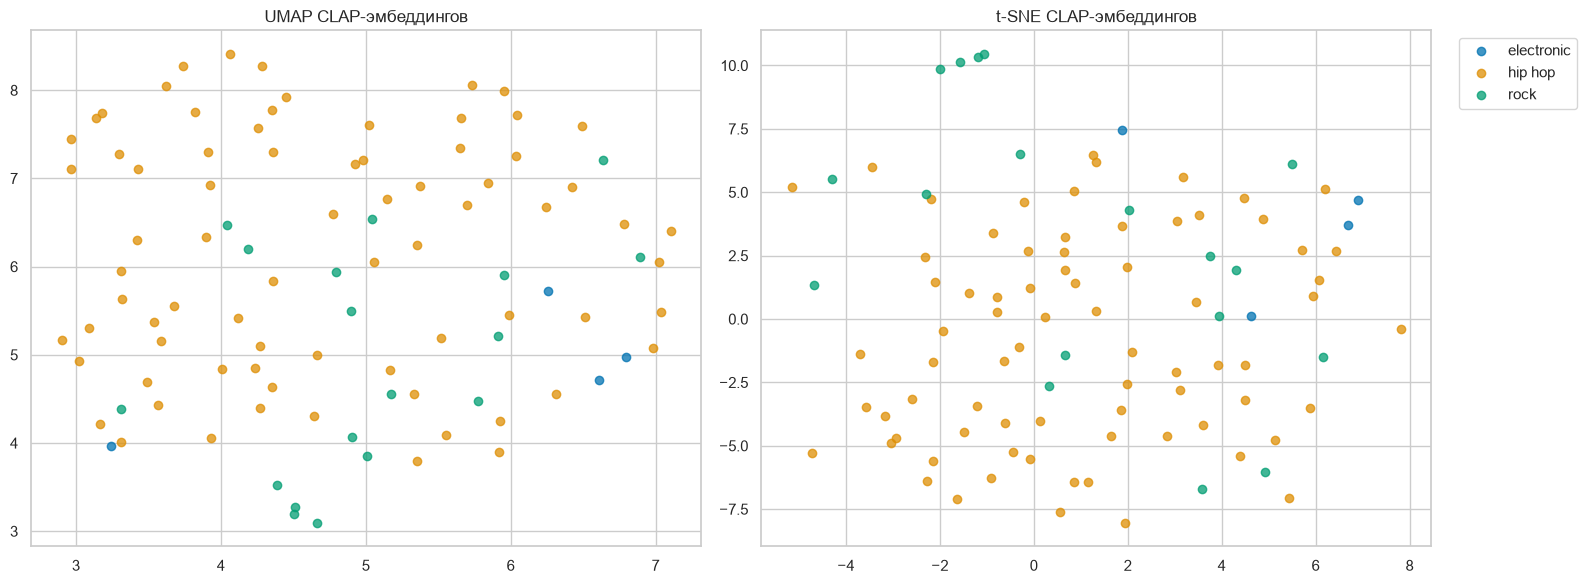

In [11]:
umap_model = umap.UMAP(
    n_components=2,
    n_neighbors=12,
    min_dist=0.15,
    metric='cosine',
    random_state=RANDOM_STATE
)
umap_points = umap_model.fit_transform(clap_embeddings)

tsne_model = TSNE(
    n_components=2,
    perplexity=20,
    init='pca',
    learning_rate='auto',
    random_state=RANDOM_STATE
)
tsne_points = tsne_model.fit_transform(clap_embeddings)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
for label in df['genre'].unique():
    mask = df['genre'] == label
    axes[0].scatter(umap_points[mask, 0], umap_points[mask, 1], label=label, alpha=0.75)
    axes[1].scatter(tsne_points[mask, 0], tsne_points[mask, 1], label=label, alpha=0.75)

axes[0].set_title('UMAP CLAP-эмбеддингов')
axes[1].set_title('t-SNE CLAP-эмбеддингов')
axes[1].legend(bbox_to_anchor=(1.03, 1), loc='upper left')
plt.tight_layout()
plt.savefig(FIGURES_DIR / 'embedding_space.png', dpi=160, bbox_inches='tight')
plt.show()

In [12]:
def nearest_indices(similarity_matrix):
    matrix = similarity_matrix.copy()
    np.fill_diagonal(matrix, -np.inf)
    return matrix.argmax(axis=1)

def playlist_neighbor_accuracy(similarity_matrix):
    neighbors = nearest_indices(similarity_matrix)
    single = df['playlist_count'].eq(1).to_numpy()
    valid = single & single[neighbors]
    names = df['playlist_name'].to_numpy()
    return float((names[valid] == names[neighbors][valid]).mean()), int(valid.sum())

single_mask = df['playlist_count'].eq(1).to_numpy()
playlist_labels = df.loc[single_mask, 'playlist_name']

low_acc, low_count = playlist_neighbor_accuracy(low_similarity)
clap_acc, clap_count = playlist_neighbor_accuracy(clap_similarity)

feature_groups = {
    'rhythm_energy': ['tempo', 'rms', 'onset_rate'],
    'spectrum': [
        'spectral_centroid', 'spectral_bandwidth', 'spectral_rolloff',
        'zero_crossing_rate', 'chroma_std'
    ],
    'mfcc': [f'mfcc_{index}' for index in range(1, 14)]
}

group_accuracy = {}
for group_name, columns in feature_groups.items():
    group_matrix = StandardScaler().fit_transform(df[columns])
    group_similarity = cosine_similarity(group_matrix)
    accuracy, comparable_count = playlist_neighbor_accuracy(group_similarity)
    group_accuracy[group_name] = {
        'accuracy': accuracy,
        'comparable_neighbors': comparable_count
    }

metrics = {
    'low_level_playlist_silhouette': float(
        silhouette_score(low_level_embeddings[single_mask], playlist_labels)
    ),
    'clap_playlist_silhouette': float(
        silhouette_score(clap_embeddings[single_mask], playlist_labels, metric='cosine')
    ),
    'low_level_same_playlist_neighbor_accuracy': low_acc,
    'clap_same_playlist_neighbor_accuracy': clap_acc,
    'low_level_comparable_neighbors': low_count,
    'clap_comparable_neighbors': clap_count,
    'rhythm_energy_same_playlist_neighbor_accuracy': group_accuracy['rhythm_energy']['accuracy'],
    'spectrum_same_playlist_neighbor_accuracy': group_accuracy['spectrum']['accuracy'],
    'mfcc_same_playlist_neighbor_accuracy': group_accuracy['mfcc']['accuracy']
}

for label_column in ['genre', 'mood', 'context']:
    low_neighbors = nearest_indices(low_similarity)
    clap_neighbors = nearest_indices(clap_similarity)
    labels = df[label_column].to_numpy()
    metrics[f'low_level_{label_column}_neighbor_agreement'] = float(
        (labels == labels[low_neighbors]).mean()
    )
    metrics[f'clap_{label_column}_neighbor_agreement'] = float(
        (labels == labels[clap_neighbors]).mean()
    )

metrics_table = pd.Series(metrics).to_frame('value')
display(metrics_table.round(3))

(DATA_DIR / 'experiment_metrics.json').write_text(
    json.dumps(metrics, ensure_ascii=False, indent=2),
    encoding='utf-8'
)

,value
low_level_playlist_silhouette,0.000
clap_playlist_silhouette,0.027
low_level_same_playlist_neighbor_accuracy,0.467
clap_same_playlist_neighbor_accuracy,0.518
low_level_comparable_neighbors,92.000
clap_comparable_neighbors,85.000
rhythm_energy_same_playlist_neighbor_accuracy,0.500
spectrum_same_playlist_neighbor_accuracy,0.424
mfcc_same_playlist_neighbor_accuracy,0.516
low_level_genre_neighbor_agreement,0.608


848

### Выводы по эксперименту

CLAP лучше сохраняет предсказанную семантику: у ближайших соседей чаще совпадают genre, mood и context. Но эти метки получены той же моделью, поэтому такое сравнение нельзя считать независимой оценкой качества.

По источнику разница небольшая. Silhouette score для обоих представлений близок к нулю, а ближайший сосед относится к тому же плейлисту примерно в половине случаев. Значит, два плейлиста не образуют хорошо разделимых аудио-кластеров и содержат похожую музыку.

Среди простых групп MFCC дали 0.516 совпадения плейлиста у ближайшего соседа, ритм и энергия — 0.500, а спектральный блок — 0.424. Объединение всех 21 low-level признаков дало 0.467: коррелирующие столбцы не всегда улучшают расстояние. Для основной похожести CLAP выглядит сильнее, потому что учитывает тембр и более сложные сочетания звуков.

### Ограничения

- плейлисты алгоритмические и могут измениться после даты снимка
- три трека встречаются в обоих источниках
- жанры и семантические признаки предсказаны zero-shot и не проверены ручной разметкой
- анализируется только 30-секундный preview
- выбранные плейлисты жанрово узкие
- 97 уникальных треков мало для устойчивой оценки рекомендательной системы
- нет истории прослушиваний и пользовательских оценок похожести

Следующий эксперимент я бы сделал с ручной оценкой 50–100 пар треков. Тогда можно сравнить CLAP и простые признаки по тому, согласны ли реальные слушатели с найденными соседями.